# 02 — Detection experiments and generalisation

            This notebook presents the binary normal-versus-fault detection evidence. It does not retrain models. It compares the earlier pooled results with the quality-controlled rerun, shows the duplicate-policy sensitivity, and then reports the separate auditorium, hospital and office models.

            The default headline feature track is the physical-signal variant. Operational-context features appear only once as a secondary sensitivity comparison in the earlier pooled results.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load saved detection artefacts

In [2]:
BASELINE = ROOT / 'results' / 'baselines'
OLD = ROOT / 'results' / 'detection'
QUALITY_MAIN = ROOT / 'results' / 'quality_controlled' / 'exclude_ambiguous_keys'
QUALITY_RETAIN = ROOT / 'results' / 'quality_controlled' / 'retain_flagged_keys'
BUILDING = ROOT / 'results' / 'building_specific'
require(
    BASELINE / 'baseline_metrics_summary.csv', OLD / 'detection_metrics_summary.csv',
    QUALITY_MAIN / 'quality_detection_metrics_by_fold.csv', QUALITY_RETAIN / 'quality_detection_metrics_by_fold.csv',
    BUILDING / 'building_detection_validation_metrics.csv', BUILDING / 'building_detection_test_metrics.csv',
)
baseline = pd.read_csv(BASELINE / 'baseline_metrics_summary.csv')
old_detection = pd.read_csv(OLD / 'detection_metrics_summary.csv')
quality_main = pd.read_csv(QUALITY_MAIN / 'quality_detection_metrics_by_fold.csv')
quality_retain = pd.read_csv(QUALITY_RETAIN / 'quality_detection_metrics_by_fold.csv')
building_validation = pd.read_csv(BUILDING / 'building_detection_validation_metrics.csv')
building_test = pd.read_csv(BUILDING / 'building_detection_test_metrics.csv')
print('Earlier pooled rows:', len(old_detection))
print('Quality-controlled fold rows:', len(quality_main))
print('Building-specific validation rows:', len(building_validation))

Earlier pooled rows: 24
Quality-controlled fold rows: 40
Building-specific validation rows: 24


## 2. Baseline comparison

In [3]:
display(baseline.round(3))

,design,baseline,folds,rows,mean_accuracy,mean_balanced_accuracy,mean_precision,mean_recall,mean_f1,mean_macro_f1,mean_false_positive_rate
0,ahu_held_out,actuator_pump_only,1,77788,0.733,0.619,0.759,0.283,0.413,0.620,0.045
1,ahu_held_out,majority_class,1,77788,0.669,0.500,0.000,0.000,0.000,0.401,0.000
2,ahu_held_out,normal_range_rule,1,77788,0.709,0.603,0.632,0.289,0.397,0.603,0.083
3,building_held_out,actuator_pump_only,3,354955,0.676,0.502,0.180,0.016,0.029,0.414,0.012
4,building_held_out,majority_class,3,354955,0.675,0.500,0.000,0.000,0.000,0.400,0.000
5,building_held_out,normal_range_rule,3,354955,0.607,0.581,0.414,0.509,0.430,0.553,0.347
6,chronological,actuator_pump_only,1,71015,0.759,0.617,0.754,0.271,0.398,0.624,0.037
7,chronological,majority_class,1,71015,0.705,0.500,0.000,0.000,0.000,0.413,0.000
8,chronological,normal_range_rule,1,71015,0.670,0.510,0.336,0.121,0.178,0.486,0.101
9,nested_grouped,actuator_pump_only,5,354955,0.728,0.649,0.677,0.393,0.494,0.654,0.095


/Users/mili/Desktop/IRPN/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


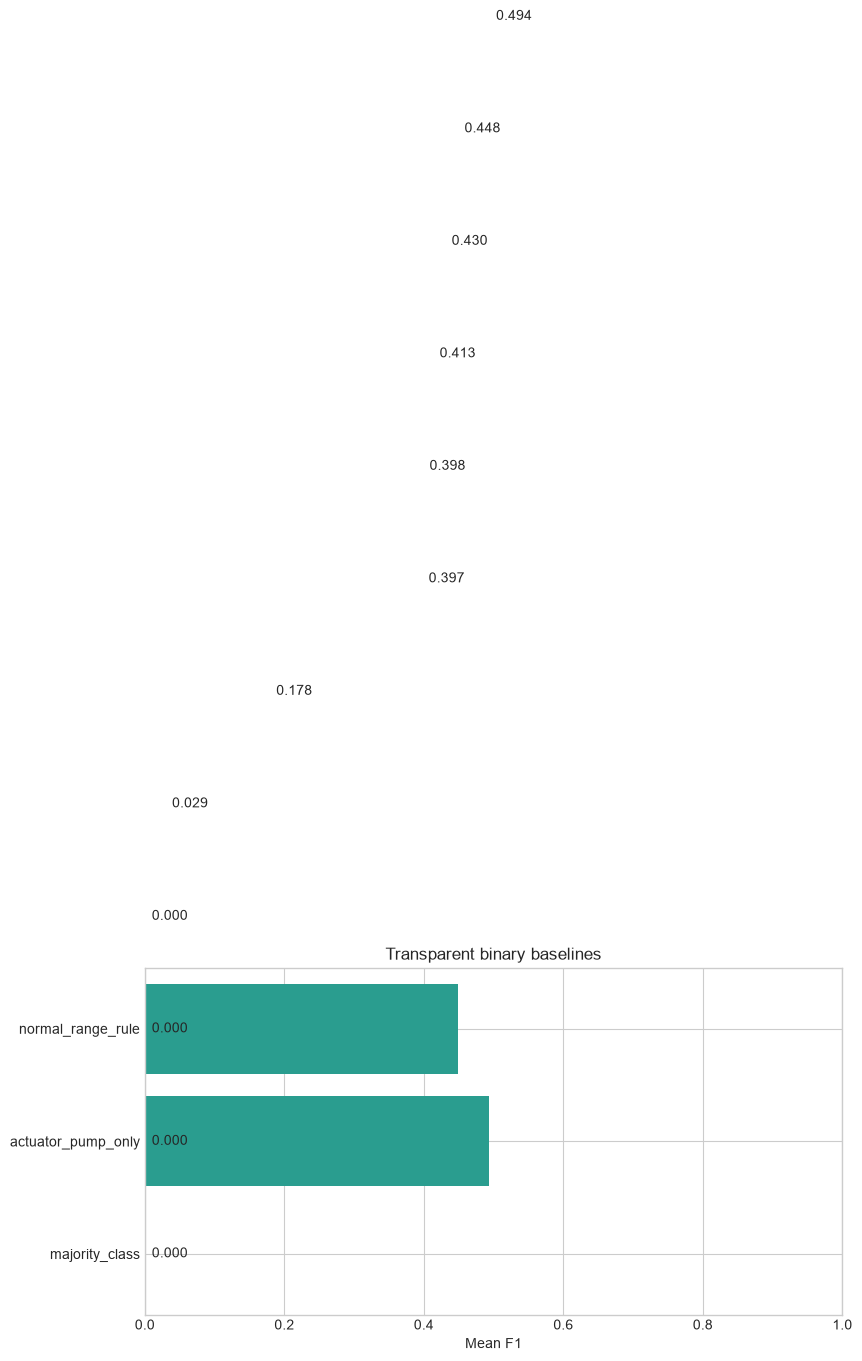

In [4]:
baseline_plot = baseline.sort_values('mean_f1')
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.barh(baseline_plot['baseline'], baseline_plot['mean_f1'], color=COLORS['accent'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean F1')
ax.set_title('Transparent binary baselines')
for index, value in enumerate(baseline_plot['mean_f1']):
    ax.text(value + 0.01, index, f'{value:.3f}', va='center')
plt.show()

The baselines are references, not competing deployment products. The normal-range rule is transparent and interpretable; the majority class is a lower bound; the actuator/pump-only baseline tests whether a small control subset is sufficient.

## 3. Earlier pooled XGBoost versus the quality-controlled rerun

In [5]:
old_xgb = old_detection[(old_detection['model'] == 'xgboost') & (old_detection['variant'] == 'physical_signal')].copy()
old_xgb = old_xgb[['design', 'mean_f1', 'mean_balanced_accuracy', 'mean_false_positive_rate']].rename(columns={
    'mean_f1': 'earlier_f1', 'mean_balanced_accuracy': 'earlier_balanced_accuracy', 'mean_false_positive_rate': 'earlier_fpr'
})
new_xgb = quality_main[quality_main['model'] == 'xgboost'].groupby('design', as_index=False).agg(
    quality_f1=('f1', 'mean'), quality_balanced_accuracy=('balanced_accuracy', 'mean'), quality_fpr=('false_positive_rate', 'mean')
)
comparison = old_xgb.merge(new_xgb, on='design', how='outer')
comparison['f1_change'] = comparison['quality_f1'] - comparison['earlier_f1']
display(comparison.round(3))

,design,earlier_f1,earlier_balanced_accuracy,earlier_fpr,quality_f1,quality_balanced_accuracy,quality_fpr,f1_change
0,ahu_held_out,0.963,0.968,0.008,0.971,0.972,0.002,0.007
1,building_held_out,0.372,0.599,0.123,0.284,0.584,0.118,-0.088
2,chronological,0.815,0.903,0.186,0.823,0.909,0.176,0.009
3,nested_grouped,0.950,0.962,0.011,0.956,0.965,0.006,0.006


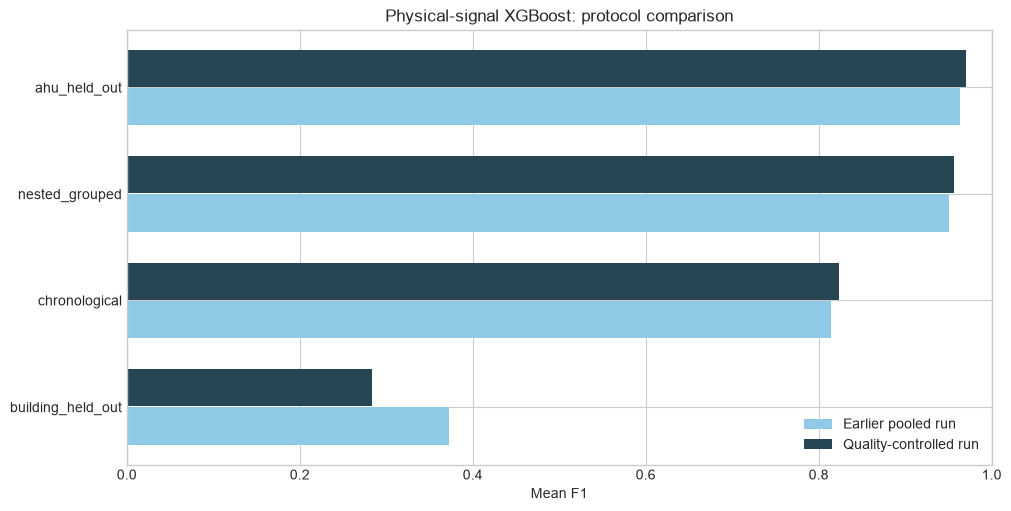

In [6]:
plot_data = comparison.sort_values('earlier_f1')
positions = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(positions - 0.18, plot_data['earlier_f1'], height=0.35, label='Earlier pooled run', color='#8ecae6')
ax.barh(positions + 0.18, plot_data['quality_f1'], height=0.35, label='Quality-controlled run', color=COLORS['dark'])
ax.set_yticks(positions, plot_data['design'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean F1')
ax.set_title('Physical-signal XGBoost: protocol comparison')
ax.legend()
plt.show()

This comparison is not a claim that the two runs are identical. The new run uses cleaned data, 88 declared physical predictors, duplicate-aware temporal processing and the quality-controlled split table. It is therefore the more defensible headline result. The main change is the harder hospital building-held-out fold.

## 4. Duplicate-policy sensitivity

In [7]:
def xgb_summary(frame, policy):
    return frame[frame['model'].eq('xgboost')].groupby('design', as_index=False).agg(
        policy=('duplicate_policy', 'first'), mean_f1=('f1', 'mean'), mean_fpr=('false_positive_rate', 'mean')
    )
duplicate_comparison = pd.concat([xgb_summary(quality_main, 'exclude'), xgb_summary(quality_retain, 'retain')], ignore_index=True)
display(duplicate_comparison.round(3))

,design,policy,mean_f1,mean_fpr
0,ahu_held_out,exclude_ambiguous_keys,0.971,0.002
1,building_held_out,exclude_ambiguous_keys,0.284,0.118
2,chronological,exclude_ambiguous_keys,0.823,0.176
3,nested_grouped,exclude_ambiguous_keys,0.956,0.006
4,ahu_held_out,retain_flagged_keys,0.969,0.003
5,building_held_out,retain_flagged_keys,0.267,0.116
6,chronological,retain_flagged_keys,0.820,0.180
7,nested_grouped,retain_flagged_keys,0.955,0.007


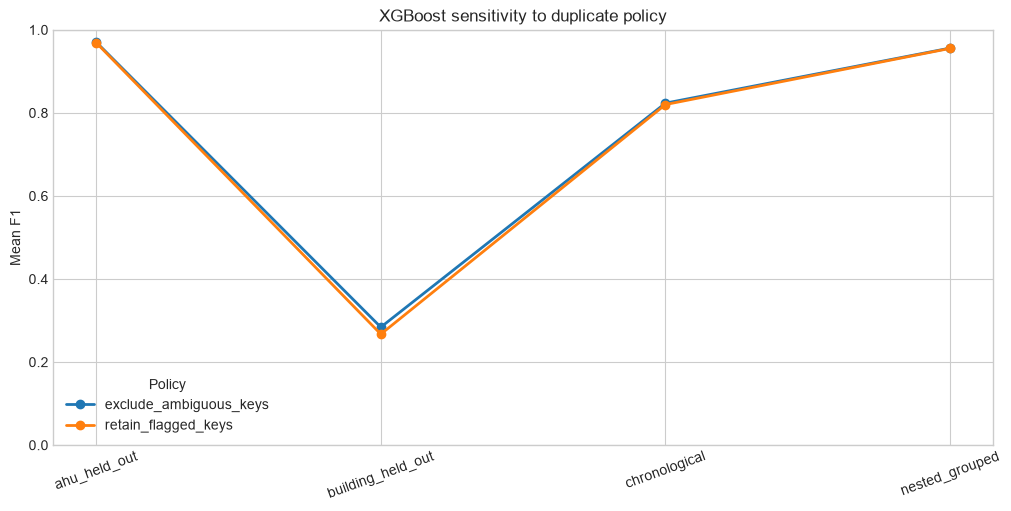

In [8]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for policy, group in duplicate_comparison.groupby('policy'):
    ax.plot(group['design'], group['mean_f1'], marker='o', linewidth=2, label=policy)
ax.set_ylim(0, 1)
ax.set_ylabel('Mean F1')
ax.set_title('XGBoost sensitivity to duplicate policy')
ax.tick_params(axis='x', rotation=20)
ax.legend(title='Policy')
plt.show()

## 5. Independent building models

In [9]:
display(building_test[['building', 'design', 'model', 'f1', 'balanced_accuracy', 'false_positive_rate', 'coverage']].round(3))

,building,design,model,f1,balanced_accuracy,false_positive_rate,coverage
0,auditorium,building_ahu_held_out,xgboost,0.997,0.997,0.002,1.0
1,auditorium,building_chronological,xgboost,1.000,1.000,0.000,1.0
2,hospital,building_ahu_held_out,xgboost,0.077,0.507,0.028,1.0
3,hospital,building_chronological,xgboost,0.880,0.958,0.043,1.0
4,office,building_ahu_held_out,xgboost,0.997,0.997,0.000,1.0
5,office,building_chronological,xgboost,0.996,0.997,0.001,1.0


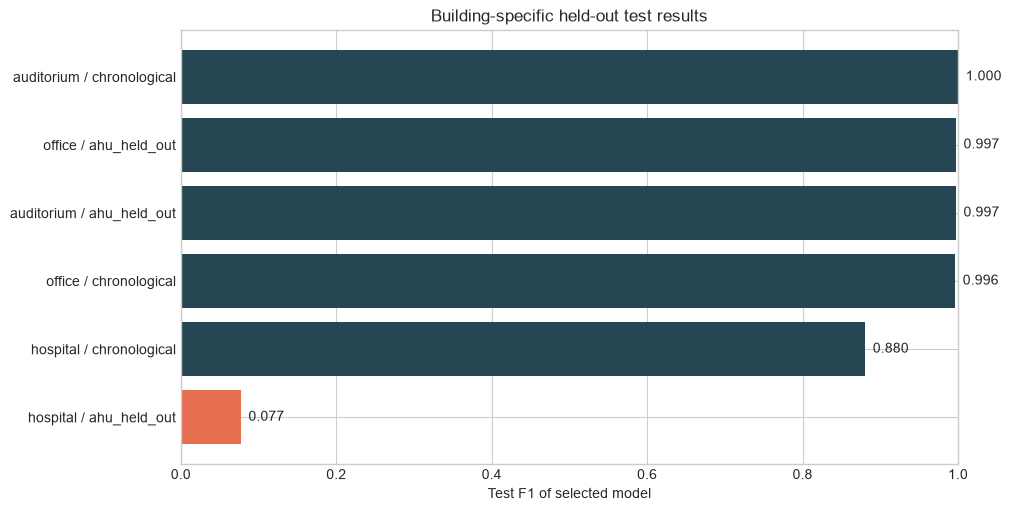

In [10]:
building_plot = building_test.copy()
building_plot['label'] = building_plot['building'] + ' / ' + building_plot['design'].str.replace('building_', '', regex=False)
building_plot = building_plot.sort_values('f1')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(building_plot['label'], building_plot['f1'], color=[COLORS['fault'] if value < 0.7 else COLORS['dark'] for value in building_plot['f1']])
ax.set_xlim(0, 1)
ax.set_xlabel('Test F1 of selected model')
ax.set_title('Building-specific held-out test results')
for index, value in enumerate(building_plot['f1']):
    ax.text(value + 0.01, index, f'{value:.3f}', va='center')
plt.show()

**Interpretation.** XGBoost was selected for all six building/design combinations. Auditorium and office are highly consistent. Hospital chronological performance is lower but usable as a research result. Hospital AHU-held-out performance is poor, showing that a model trained on some hospital AHUs does not automatically generalise to unseen hospital AHUs.

## 6. What the experiments do and do not establish

In [11]:
conclusions = pd.DataFrame([
    ['Within-building grouped evaluation', 'Strong XGBoost results', 'Useful evidence for the labelled buildings and split design'],
    ['Chronological evaluation', 'Strong for auditorium/office; lower for hospital', 'Temporal drift and building-specific calibration matter'],
    ['Unseen-building evaluation', 'Much weaker, especially hospital', 'Cross-building deployment cannot be assumed'],
    ['Duplicate sensitivity', 'Small change between policies', 'Headline pooled result is not driven by duplicate rows'],
], columns=['question', 'observed result', 'responsible interpretation'])
display(conclusions)

,question,observed result,responsible interpretation
0,Within-building grouped evaluation,Strong XGBoost results,Useful evidence for the labelled buildings and...
1,Chronological evaluation,Strong for auditorium/office; lower for hospital,Temporal drift and building-specific calibrati...
2,Unseen-building evaluation,"Much weaker, especially hospital",Cross-building deployment cannot be assumed
3,Duplicate sensitivity,Small change between policies,Headline pooled result is not driven by duplic...
